In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_openml

boston = fetch_openml(name="boston", version=1, as_frame=True, parser="auto")
df = boston.frame.astype(float)

print(df.shape)  # expect (506, 14)
df.head()

(506, 14)


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,396.90,5.33,36.2


In [3]:
print(df.info())
print("\nMissing values per column:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    float64
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    float64
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(14)
memory usage: 55.5 KB
None

Missing values per column:
 CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64

Duplicate rows:

,count,mean,std,min,25%,50%,75%,max
CRIM,506.0,3.613524,8.601545,0.00632,0.082045,0.25651,3.677083,88.9762
ZN,506.0,11.363636,23.322453,0.00000,0.000000,0.00000,12.500000,100.0000
INDUS,506.0,11.136779,6.860353,0.46000,5.190000,9.69000,18.100000,27.7400
CHAS,506.0,0.069170,0.253994,0.00000,0.000000,0.00000,0.000000,1.0000
NOX,506.0,0.554695,0.115878,0.38500,0.449000,0.53800,0.624000,0.8710
RM,506.0,6.284634,0.702617,3.56100,5.885500,6.20850,6.623500,8.7800
AGE,506.0,68.574901,28.148861,2.90000,45.025000,77.50000,94.075000,100.0000
DIS,506.0,3.795043,2.105710,1.12960,2.100175,3.20745,5.188425,12.1265
RAD,506.0,9.549407,8.707259,1.00000,4.000000,5.00000,24.000000,24.0000
TAX,506.0,408.237154,168.537116,187.00000,279.000000,330.00000,666.000000,711.0000


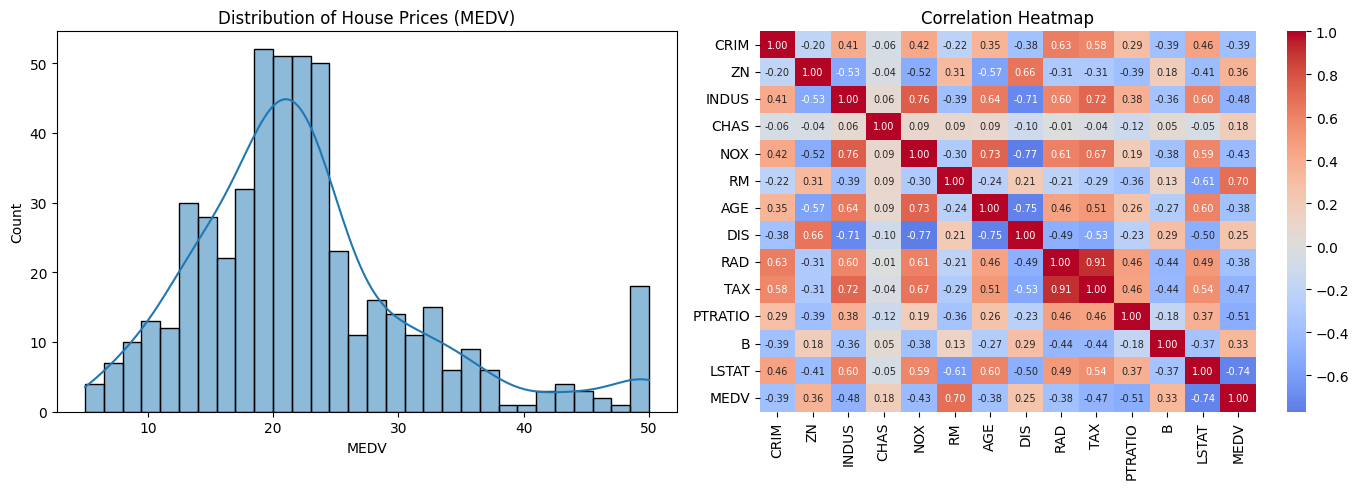

MEDV       1.000000
RM         0.695360
ZN         0.360445
B          0.333461
DIS        0.249929
CHAS       0.175260
AGE       -0.376955
RAD       -0.381626
CRIM      -0.388305
NOX       -0.427321
TAX       -0.468536
INDUS     -0.483725
PTRATIO   -0.507787
LSTAT     -0.737663
Name: MEDV, dtype: float64


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["MEDV"], bins=30, kde=True, ax=ax[0])
ax[0].set_title("Distribution of House Prices (MEDV)")

sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, annot_kws={"size": 7}, ax=ax[1])
ax[1].set_title("Correlation Heatmap")

plt.tight_layout()
plt.show()

print(df.corr()["MEDV"].sort_values(ascending=False))

In [5]:
from sklearn.model_selection import train_test_split

X = df.drop("MEDV", axis=1)
y = df["MEDV"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(X_train.shape, X_test.shape)  # (404, 13) (102, 13)

(404, 13) (102, 13)


In [6]:
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

model = XGBRegressor(n_estimators=300, learning_rate=0.05,
                     max_depth=4, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("R2 :", round(r2_score(y_test, y_pred), 4))
print("MAE:", round(mean_absolute_error(y_test, y_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 4))

R2 : 0.9028
MAE: 1.9119
RMSE: 2.6703


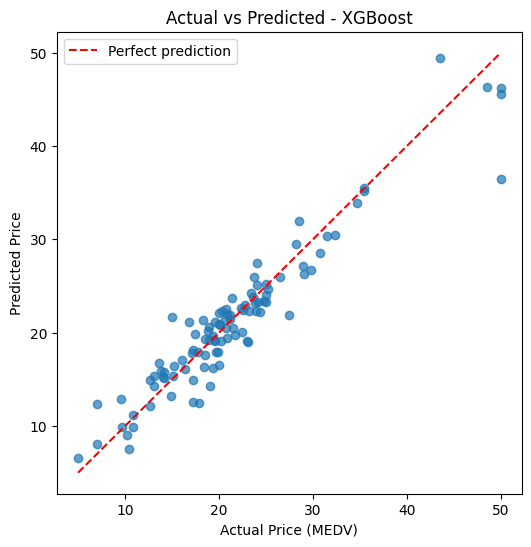

In [7]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.7)
plt.plot([y.min(), y.max()], [y.min(), y.max()], "r--", label="Perfect prediction")
plt.xlabel("Actual Price (MEDV)")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted - XGBoost")
plt.legend()
plt.show()

In [8]:
from sklearn.model_selection import cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=300, learning_rate=0.05,
                            max_depth=4, random_state=42),
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)
rows = []

for name, m in models.items():
    r2 = cross_val_score(m, X, y, cv=kf, scoring="r2")
    mae = -cross_val_score(m, X, y, cv=kf, scoring="neg_mean_absolute_error")
    # also get the single 80:20 test-set result
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    rows.append({
        "Model": name,
        "CV R2 (mean)": round(r2.mean(), 4),
        "CV R2 (std)": round(r2.std(), 4),
        "CV MAE (mean)": round(mae.mean(), 4),
        "Test R2": round(r2_score(y_test, p), 4),
        "Test MAE": round(mean_absolute_error(y_test, p), 4),
    })

results = pd.DataFrame(rows).set_index("Model")
results

,CV R2 (mean),CV R2 (std),CV MAE (mean),Test R2,Test MAE
Model,,,,,
Linear Regression,0.7152,0.0375,3.3885,0.6688,3.1891
Random Forest,0.8713,0.0340,2.2154,0.8783,2.0778
XGBoost,0.8956,0.0182,2.0439,0.9028,1.9119


In [9]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    "n_estimators": [200, 300, 500, 800],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "max_depth": [3, 4, 5, 6],
    "subsample": [0.7, 0.85, 1.0],
    "colsample_bytree": [0.7, 0.85, 1.0],
    "min_child_weight": [1, 3, 5],
}

search = RandomizedSearchCV(
    XGBRegressor(random_state=42),
    param_distributions=param_dist,
    n_iter=40, cv=5, scoring="r2",
    random_state=42, n_jobs=-1
)
search.fit(X_train, y_train)

print("Best params:", search.best_params_)
print("Best CV R2 :", round(search.best_score_, 4))

best = search.best_estimator_
p = best.predict(X_test)
print("Tuned Test R2 :", round(r2_score(y_test, p), 4))
print("Tuned Test MAE:", round(mean_absolute_error(y_test, p), 4))

Best params: {'subsample': 0.7, 'n_estimators': 800, 'min_child_weight': 1, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 0.7}
Best CV R2 : 0.8535
Tuned Test R2 : 0.89
Tuned Test MAE: 1.9078


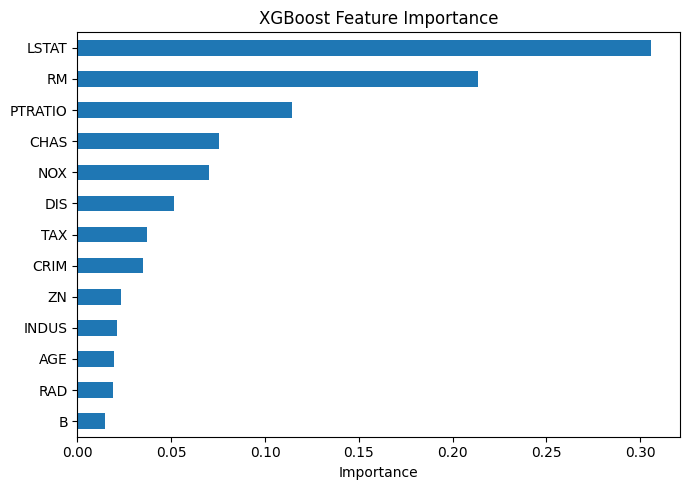

In [10]:
imp = pd.Series(best.feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", figsize=(7, 5), title="XGBoost Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [11]:
import joblib
from google.colab import files

final_model = best   # or: model, if tuning didn't beat it
joblib.dump(final_model, "xgb_model.pkl")
files.download("xgb_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
from google.colab import files
import xgboost

final_model = best   # use `model` instead if tuning didn't beat 0.9028 test R2
final_model.save_model("xgb_model.json")
files.download("xgb_model.json")
print(xgboost.__version__)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

3.4.1


In [ ]:
!pip install -q gradio

import gradio as gr
import pandas as pd

cols = list(X.columns)

def predict(*vals):
    row = pd.DataFrame([vals], columns=cols)
    price = float(final_model.predict(row)[0]) * 1000   # MEDV is in $1000s
    return f"${price:,.0f}"

inputs = [
    gr.Slider(0.0, 90.0, value=0.25, step=0.01, label="CRIM - Crime rate per capita"),
    gr.Slider(0.0, 100.0, value=0.0, step=0.5, label="ZN - Large residential lots (%)"),
    gr.Slider(0.0, 28.0, value=9.7, step=0.1, label="INDUS - Non-retail business acres (%)"),
    gr.Slider(0, 1, value=0, step=1, label="CHAS - Borders Charles River (1 = yes)"),
    gr.Slider(0.38, 0.88, value=0.54, step=0.01, label="NOX - Nitric oxide concentration"),
    gr.Slider(3.5, 9.0, value=6.2, step=0.1, label="RM - Average rooms per dwelling"),
    gr.Slider(0.0, 100.0, value=77.5, step=0.5, label="AGE - Homes built before 1940 (%)"),
    gr.Slider(1.0, 12.5, value=3.2, step=0.1, label="DIS - Distance to employment centres"),
    gr.Slider(1, 24, value=5, step=1, label="RAD - Highway accessibility index"),
    gr.Slider(180, 720, value=330, step=1, label="TAX - Property tax rate"),
    gr.Slider(12.0, 22.5, value=19.0, step=0.1, label="PTRATIO - Pupil-teacher ratio"),
    gr.Slider(0.0, 400.0, value=391.4, step=0.5, label="B - Demographic index"),
    gr.Slider(1.0, 38.0, value=11.4, step=0.1, label="LSTAT - Lower-status population (%)"),
]

app = gr.Interface(
    fn=predict,
    inputs=inputs,
    outputs=gr.Textbox(label="Estimated median home value"),
    live=True,
    title="House Price Predictor",
    description="XGBoost model trained on the Boston Housing dataset. "
                "Academic demo: predictions reflect 1970s data, not current prices. "
                "Typical error is about $1,900.",
    flagging_mode="never",
)

app.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://efa413ca80a549990b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/gradio/blocks.py", line 2181, in preprocess_data
    processed_value = await anyio.to_thread.run_sync(
                      ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
        block.preprocess, inputs_cached, limiter=self.limiter
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/anyio/to_thread.py", line 65, in run_sync
    return await get_async_backend().run_sync_in_worker_thread(
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
        func, args, abandon_on_cancel=abandon_on_cancel, limiter=limiter
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/anyio/_backends/_asyncio.py", line 2706, in run_sync_in_worker_thread
    return await future
           ^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/anyio/_backends/_asyncio.py", line